[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bethavila17/dncp-riesgo-contrataciones/blob/main/notebooks/01_captura_y_almacenamiento.ipynb)

# 1. Captura multifuente y almacenamiento escalable
**Proyecto III Big Data — Maestría en Ciencia de Datos (UCOM)** · Bethania Avila, Arturo Fernández, Gustavo Bogado

**Objetivo 1 del TP:** recopilar y almacenar datos de múltiples fuentes. **Objetivo 2:** infraestructura de almacenamiento escalable.

| # | Fuente | Tipo | Frecuencia | Uso |
|---|---|---|---|---|
| 1 | OCP Data Registry (copia de la API de la DNCP) | JSON Lines anidado (OCDS), un archivo por año | mensual | histórico 2020–2026 |
| 2 | API REST OCDS v3 de la DNCP | JSON por proceso | cada hora | micro-lotes de procesos nuevos (velocidad) |
| 3 | Módulo de protestas y denuncias de la DNCP | ZIP con CSV + huellas SHA-256 | diaria | casos de referencia |
| 4 | API del Banco Mundial | JSON | anual | tipo de cambio e IPC (montos comparables) |

In [1]:
# Configuración del entorno (Google Colab o local)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/bethavila17/dncp-riesgo-contrataciones.git"  # <- URL del repositorio en GitHub
USAR_DRIVE = False  # True: guarda el data lake en Google Drive y no repite descargas entre sesiones

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/dncp-riesgo-contrataciones")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(RAIZ / "requirements-colab.txt")], check=True)
    if USAR_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ["DNCP_DATA_DIR"] = "/content/drive/MyDrive/dncp_data_lake"
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dncp_riesgo import graficos as gr
from dncp_riesgo.pipeline import asegurar_datos, preparar

cfg, lake = preparar()
gr.estilo()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| años:", cfg["fuentes"]["ocp_registry"]["anios"])

Entorno: local | años: [2020, 2021, 2022, 2023, 2024, 2025, 2026]


In [2]:
asegurar_datos(lake, cfg, hasta="gold")

22:12:39 | dncp | Datos listos hasta la etapa 'gold' (no se repite el procesamiento).


## 1.1 Capa bronze: qué se descargó y con qué huella (trazabilidad)

In [3]:
pd.read_csv(lake.ruta("bronze", "manifiesto.csv"))

,fuente,anio,archivo,MB,sha256,registrado
0,OCP Data Registry,2020,2020.jsonl.gz,55.5,a754cc939a2534a5bae924d053529f8436d4acaec335c11de0428cbd0fce859d,2026-11-10 21:30
1,OCP Data Registry,2021,2021.jsonl.gz,56.8,d6e816f1326fe5ecdf7791dad2a8d6d95c8ba16fbc32db4a5d5d48d6cf813e21,2026-11-10 21:30
2,OCP Data Registry,2022,2022.jsonl.gz,197.2,683b154ab97adb8dcffdba377b186e6a3054c22ff0934d6d885a881caad8a402,2026-11-10 21:30
3,OCP Data Registry,2023,2023.jsonl.gz,120.5,53169c5b169bbcc73fe88dfbb3a90a63db35fba9702172fd74f50a51f2039935,2026-11-10 21:30
4,OCP Data Registry,2024,2024.jsonl.gz,176.9,9884f54dee5dd1dc2caef961d9d562ccf61542a6379c09a026a5bcdb90011ebd,2026-11-10 21:30
5,OCP Data Registry,2025,2025.jsonl.gz,173.3,d9d20c0fb1392c7594ae7efcee05dc80d7c9b3df992e17d29178e6b15e10c4d2,2026-11-10 21:30
6,OCP Data Registry,2026,2026.jsonl.gz,101.6,b939ec8c9a5d97c7ccc5dae2042a3daf5177e96a65a5d759f2d7d765efa0a67d,2026-11-10 21:30
7,Protestas DNCP,2020,com-masivo.zip,2.5,7004b27c29a4ee12ff8572b8694a3a15c8798d659934273b98442f56a95b7a91,2026-11-10 21:30
8,Protestas DNCP,2021,com-masivo.zip,2.4,05bcb01ed1c2a4601421cfc06062625f224b1112dbfb48ba1251a451fa2b4339,2026-11-10 21:30
9,Protestas DNCP,2022,com-masivo.zip,7.4,98c471d8c7ddb45958509d94962140b1fbb7fa34cd4399945e1bce9966fac3ec,2026-11-10 21:30


## 1.2 Volumen: inventario de los objetos anidados del JSON
Cada objeto anidado (ítem, documento, pago, parte…) sería una fila si el JSON se aplanara a tablas.

In [4]:
from dncp_riesgo.almacenamiento import ENTIDADES_INVENTARIO
inv = lake.leer_gold("inventario_volumen").sort_values("lote")
cols_n = [f"n_{e}" for e in ENTIDADES_INVENTARIO]
inv["objetos_anidados"] = inv[cols_n].sum(axis=1)
display(inv[["lote", "MB_gzip", "MB_json", "n_procesos", "objetos_anidados", "segundos"]])
tot = inv[["MB_gzip", "MB_json", "n_procesos", "objetos_anidados"]].sum()
print(f"Total: {tot.MB_gzip/1024:.2f} GB comprimidos | {tot.MB_json/1024:.1f} GB de JSON | "
      f"{tot.n_procesos:,.0f} procesos | {tot.objetos_anidados:,.0f} objetos anidados".replace(",", "."))

,lote,MB_gzip,MB_json,n_procesos,objetos_anidados,segundos
0,ocp_2020,55.5,491.7,10270,540372,22.0
1,ocp_2021,56.8,496.3,9276,545477,22.2
2,ocp_2022,197.2,1867.0,29539,2074068,115.1
3,ocp_2023,120.5,1168.0,12657,1209615,67.8
4,ocp_2024,176.9,1981.2,12470,2185835,124.3
5,ocp_2025,173.3,2082.6,10876,2449827,132.7
6,ocp_2026,101.6,1239.3,5382,1495409,81.6


Total: 0.86 GB comprimidos | 9.1 GB de JSON | 90.470 procesos | 10.500.603 objetos anidados


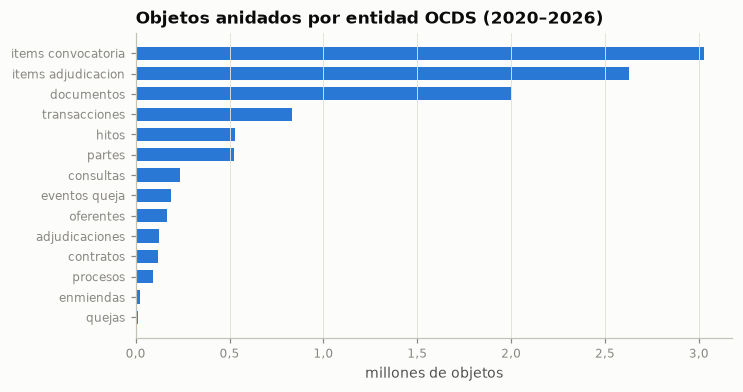

In [5]:
por_entidad = inv[cols_n].sum().rename(lambda c: c[2:].replace("_", " ")).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(por_entidad.index, por_entidad.values / 1e6, color=gr.SERIES[0], height=0.65)
ax.set_xlabel("millones de objetos"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(gr.formato_es(1))
ax.set_title("Objetos anidados por entidad OCDS (2020–2026)")
gr.guardar(fig, "fig01_volumen"); plt.show()

## 1.3 Veracidad: verificación de integridad de la fuente 3
Cada CSV del módulo de protestas se compara con la huella SHA-256 que publica la DNCP.

In [6]:
lake.leer_gold("verificacion_protestas")

,anio,quejas,procesos,csv_verificados_sha256,csv_correctos
0,2020,1108,711,6,6
1,2021,995,594,6,6
2,2022,2990,1885,6,6
3,2023,1720,1006,6,6
4,2024,2160,1213,6,6
5,2025,1905,938,6,6
6,2026,1901,873,6,6


## 1.4 Fuente 2 (velocidad): micro-lote desde la API de la DNCP
Se traen los procesos adjudicados en los últimos días. Sin credenciales la API admite ~15 llamadas por minuto.

In [7]:
from dncp_riesgo.ingesta import ingesta_incremental
info = ingesta_incremental(lake, cfg, dias=3, max_procesos=5)
info

22:13:17 | dncp | API DNCP: 317 procesos encontrados, se descargan 5


22:13:35 | dncp | API DNCP /ocds/record/ocds-03ad3f-444653-1 (intento 1/4): ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))


{'lote': 'api_20261110T221358',
 'ocids': ['ocds-03ad3f-454727-1',
  'ocds-03ad3f-455643-1',
  'ocds-03ad3f-446762-1',
  'ocds-03ad3f-444653-1',
  'ocds-03ad3f-459389-1'],
 'procesos': 5,
 'llamadas_api': 9,
 'segundos': 70.5,
 'archivo_bronze': 'bronze\\api_dncp\\fecha=2026-11-10\\lote_20261110T221358.jsonl.gz'}

## 1.5 Fuente 4: indicadores macroeconómicos

In [8]:
pd.read_parquet(lake.ruta("silver", "macro")).query("2019 <= anio <= 2026")

,anio,tipo_cambio,ipc,deflactor,lote
9,2019,6240.722078,143.821041,1.323089,banco_mundial
10,2020,6771.097425,146.363101,1.300110,banco_mundial
11,2021,6774.162735,153.370941,1.240705,banco_mundial
12,2022,6982.752378,168.348483,1.130322,banco_mundial
13,2023,7288.872054,176.146423,1.080283,banco_mundial
14,2024,7560.247588,182.902348,1.040381,banco_mundial
15,2025,7545.446755,190.288062,1.000000,banco_mundial
16,2026,7545.446755,190.288062,1.000000,banco_mundial


## 1.6 Data lake por capas
```
bronze/  datos crudos de cada fuente (JSONL.gz, ZIP, JSON) + manifiesto con SHA-256
silver/  7 tablas normalizadas en Parquet (Zstd), particionadas por lote de ingesta
gold/    indicadores, puntajes, evaluaciones, redes y pronósticos
```
El catálogo es DuckDB: vistas SQL sobre los Parquet, sin copiarlos. El mismo diseño funciona en disco local, Google Drive o un bucket (S3/GCS) y lo lee también Spark (notebook 06).

In [9]:
resumen = lake.resumen()
display(resumen)
bronze = resumen.query("capa == 'bronze'")["MB"].sum(); silver = resumen.query("capa == 'silver'")["MB"].sum()
print(f"bronze {bronze:,.0f} MB -> silver {silver:,.0f} MB (factor {bronze/silver:.1f}x)")

,capa,tabla,archivos,particiones,MB
0,bronze,api_dncp,3,1,0.7
1,bronze,banco_mundial,1,1,0.0
2,bronze,ocp_registry,7,7,881.8
3,bronze,protestas_dncp,7,7,30.7
4,silver,adjudicaciones,10,10,4.0
5,silver,contratos,10,10,3.9
6,silver,items,10,10,130.0
7,silver,macro,1,1,0.0
8,silver,oferentes,10,10,1.8
9,silver,partes,10,10,6.5


bronze 913 MB -> silver 156 MB (factor 5.8x)


In [10]:
con = lake.conectar()
con.sql("""
    SELECT year(coalesce(fecha_inicio_convocatoria, fecha_publicacion)) AS anio,
           count(*) AS procesos, sum(n_items) AS items, sum(n_quejas) AS quejas
    FROM procesos_v
    WHERE coalesce(fecha_inicio_convocatoria, fecha_publicacion) >= '2020-01-01'
    GROUP BY 1 ORDER BY 1
""").df()

,anio,procesos,items,quejas
0,2020,9120,194378.0,2077.0
1,2021,9619,179694.0,1736.0
2,2022,10365,336586.0,1834.0
3,2023,9477,444879.0,1712.0
4,2024,8309,604025.0,981.0
5,2025,8742,652925.0,845.0
6,2026,2989,234768.0,144.0


## 1.7 Benchmarks que justifican el diseño

In [11]:
from dncp_riesgo.procesamiento.benchmark import benchmark_formatos, benchmark_motores, consulta_proveedor
benchmark_formatos(lake)

,formato,filas,MB,escritura_s,consulta_s
0,CSV (texto plano),1608243,356.1,7.91,2.234
1,CSV comprimido (gzip),1608243,42.7,106.77,10.503
2,Parquet Snappy,1608243,57.4,8.24,0.262
3,Parquet Zstd,1608243,33.3,11.06,0.285


In [12]:
benchmark_motores(lake)

,motor,segundos
0,pandas (en memoria),6.89
1,"DuckDB (columnar, vectorizado)",0.69


**Consulta operativa:** dado un proveedor (RUC), ¿qué contratos obtuvo, con qué entidades y por qué montos?

In [13]:
ruc = con.sql("SELECT proveedor_id FROM indicadores WHERE proveedor_id IS NOT NULL GROUP BY 1 ORDER BY count(*) DESC LIMIT 1").fetchall()[0][0]
tabla, ms = consulta_proveedor(lake, ruc, con)
print(f"{len(tabla)} procesos del proveedor {ruc} en {ms:.0f} ms")
tabla.head(10)

554 procesos del proveedor PY-RUC-80013889-9 en 456 ms


,fecha,entidad,titulo,modalidad,monto_millones_gs,n_oferentes
0,2026-07-07,Dirección Nacional de Correos del Paraguay (DINACOPA),ADQUISION DE IMPRESORAS MULTIFUNCION PARA LA DINACOPA,Menor cuantía / Directa,50.1,2.0
1,2026-06-25,Universidad Nacional de Asunción (UNA),"Adquisición de Escáneres para Sede Central, Filiales y CAES",Menor cuantía / Directa,44.7,2.0
2,2026-06-17,Universidad Politécnica Taiwán – Paraguay (UPTP),MCN N°18/2025 - SERVICIO DE IMPRESIÓN Y FOTOCOPIADO PARA LA UPTP - CONTRATO ABIERTO PO...,Menor cuantía / Directa,120.0,1.0
3,2026-05-12,Universidad Nacional de Asunción (UNA),Alquiler de equipos de impresoras.,Menor cuantía / Directa,95.9,1.0
4,2026-05-08,Corte Suprema de Justicia (CSJ),ADQUISICIÓN DE TÓNER Y OTROS (Ad Referéndum),Menor cuantía / Directa,85.2,NaN
5,2026-05-08,Secretaria de Defensa del Consumidor y el Usuario (SEDECO),SERVICIO DE ALQUILER DE FOTOCOPIADORAS - PLURIANUAL,Menor cuantía / Directa,93.6,1.0
6,2026-05-06,Ministerio de Salud Pública y Bienestar Social (MSPBS),"Contratación del Servicio de Copiado, Escaneo e Impresión para el Hospital Nacional de...",Menor cuantía / Directa,300.0,1.0
7,2026-04-30,Corte Suprema de Justicia (CSJ),"Adquisición de Fotocopiadoras, Proyectores, Relojes Biométricos, Switches, Monitores y...",Menor cuantía / Directa,94.1,3.0
8,2026-04-20,Presidencia de la República,SERVICIOS DE IMPRESIÓN Y COPIADO CON CONTRATO ABIERTO - PLURIANUAL,Menor cuantía / Directa,97.8,1.0
9,2026-03-27,Ministerio de Defensa Nacional (MDN),SERVICIO DE IMPRESIÓN Y FOTOCOPIADO PARA EL COMANDO DE LAS FUERZAS MILITARES (PLURIANU...,Menor cuantía / Directa,396.0,2.0
